<a href="https://colab.research.google.com/github/Mikhailo88/MN-Praktychni-K4/blob/main/%D0%9B%D0%A04_%D0%9E%D0%BB%D1%8C%D1%85%D0%BE%D0%B2%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A24_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import os

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
)

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
print("Path to dataset files:", path)

100%|██████████| 18.1k/18.1k [00:00<00:00, 11.1MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/hellbuoy/car-price-prediction/versions/1


In [16]:
from google.colab import files

uploaded = files.upload()

Saving CarPrice_Assignment.csv to CarPrice_Assignment (1).csv


In [17]:
df = pd.read_csv("CarPrice_Assignment.csv")
df

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,201,-1,volvo 145e (sw),gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0
201,202,-1,volvo 144ea,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0
202,203,-1,volvo 244dl,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0
203,204,-1,volvo 246,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470.0


**car_ID**	Унікальний ідентифікатор автомобіля.

**symboling**	Оцінка рівня ризику автомобіля за страховою класифікацією.

**CarName**	Марка та назва моделі автомобіля.

**fueltype**	Тип палива: бензин (gas) або дизель (diesel).

**aspiration**	Тип системи подачі повітря в двигун: стандартна (std) або турбонаддув (turbo).

**doornumber**	Кількість дверей автомобіля.

**carbody**	Тип кузова: седан, хетчбек, універсал, кабріолет тощо.

**drivewheel**	Тип приводу: передній (fwd), задній (rwd) або повний (4wd).

**enginelocation**	Розташування двигуна: спереду (front) або ззаду (rear).

**wheelbase**	Колісна база — відстань між передньою та задньою осями коліс.

**enginesize**	Робочий об’єм двигуна.

**fuelsystem** Тип системи подачі палива в двигун.

**boreratio**	Діаметр циліндра двигуна відносно інших його параметрів; фактично діаметр циліндра.

**stroke**	Хід поршня в циліндрі двигуна.

**compressionratio**	Ступінь стиснення паливно-повітряної суміші в двигуні.

**horsepower**	Потужність двигуна в кінських силах.

**peakrpm**	Частота обертання двигуна, за якої досягається максимальна потужність, об/хв.

**citympg**	Паливна економічність автомобіля в міському режимі, у милях на галон.

**highwaympg**	Паливна економічність автомобіля на трасі, у милях на галон.

**price**	Ціна автомобіля. Це цільова змінна для побудови моделі прогнозування вартості.

## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [18]:
print(df.isnull().sum())

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64


In [9]:
print(df.isnull().sum().sum())

0


In [10]:
print(df.duplicated().sum())

0


In [11]:
print(df.drop(columns=["car_ID"]).duplicated().sum())

0


In [19]:
print(df.nunique())

car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight          171
enginetype            7
cylindernumber        7
enginesize           44
fuelsystem            8
boreratio            38
stroke               37
compressionratio     32
horsepower           59
peakrpm              23
citympg              29
highwaympg           30
price               189
dtype: int64


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [20]:
# car_ID зберігаємо для фінального виведення прогнозів, але не подаємо в модель
ids = df["car_ID"].copy()

# CarName має дуже високу кардинальність. Для цієї реалізації залишимо тільки марку автомобіля.
df_model = df.copy()
df_model["CarName"] = (
    df_model["CarName"]
    .str.split()
    .str[0]
    .str.lower()
    .replace({
        "maxda": "mazda",
        "porcshce": "porsche",
        "toyouta": "toyota",
        "vokswagen": "volkswagen",
        "vw": "volkswagen"
    })
)

df_model = df_model.drop(columns=["car_ID", "CarName"])

In [23]:
df_model

,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,1,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,2,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,2,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0
201,-1,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.8,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0
202,-1,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0
203,-1,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470.0


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


In [25]:
numeric_initial = df.select_dtypes(include="number").columns.drop(
    ["car_ID", "price"],
    errors="ignore"
)

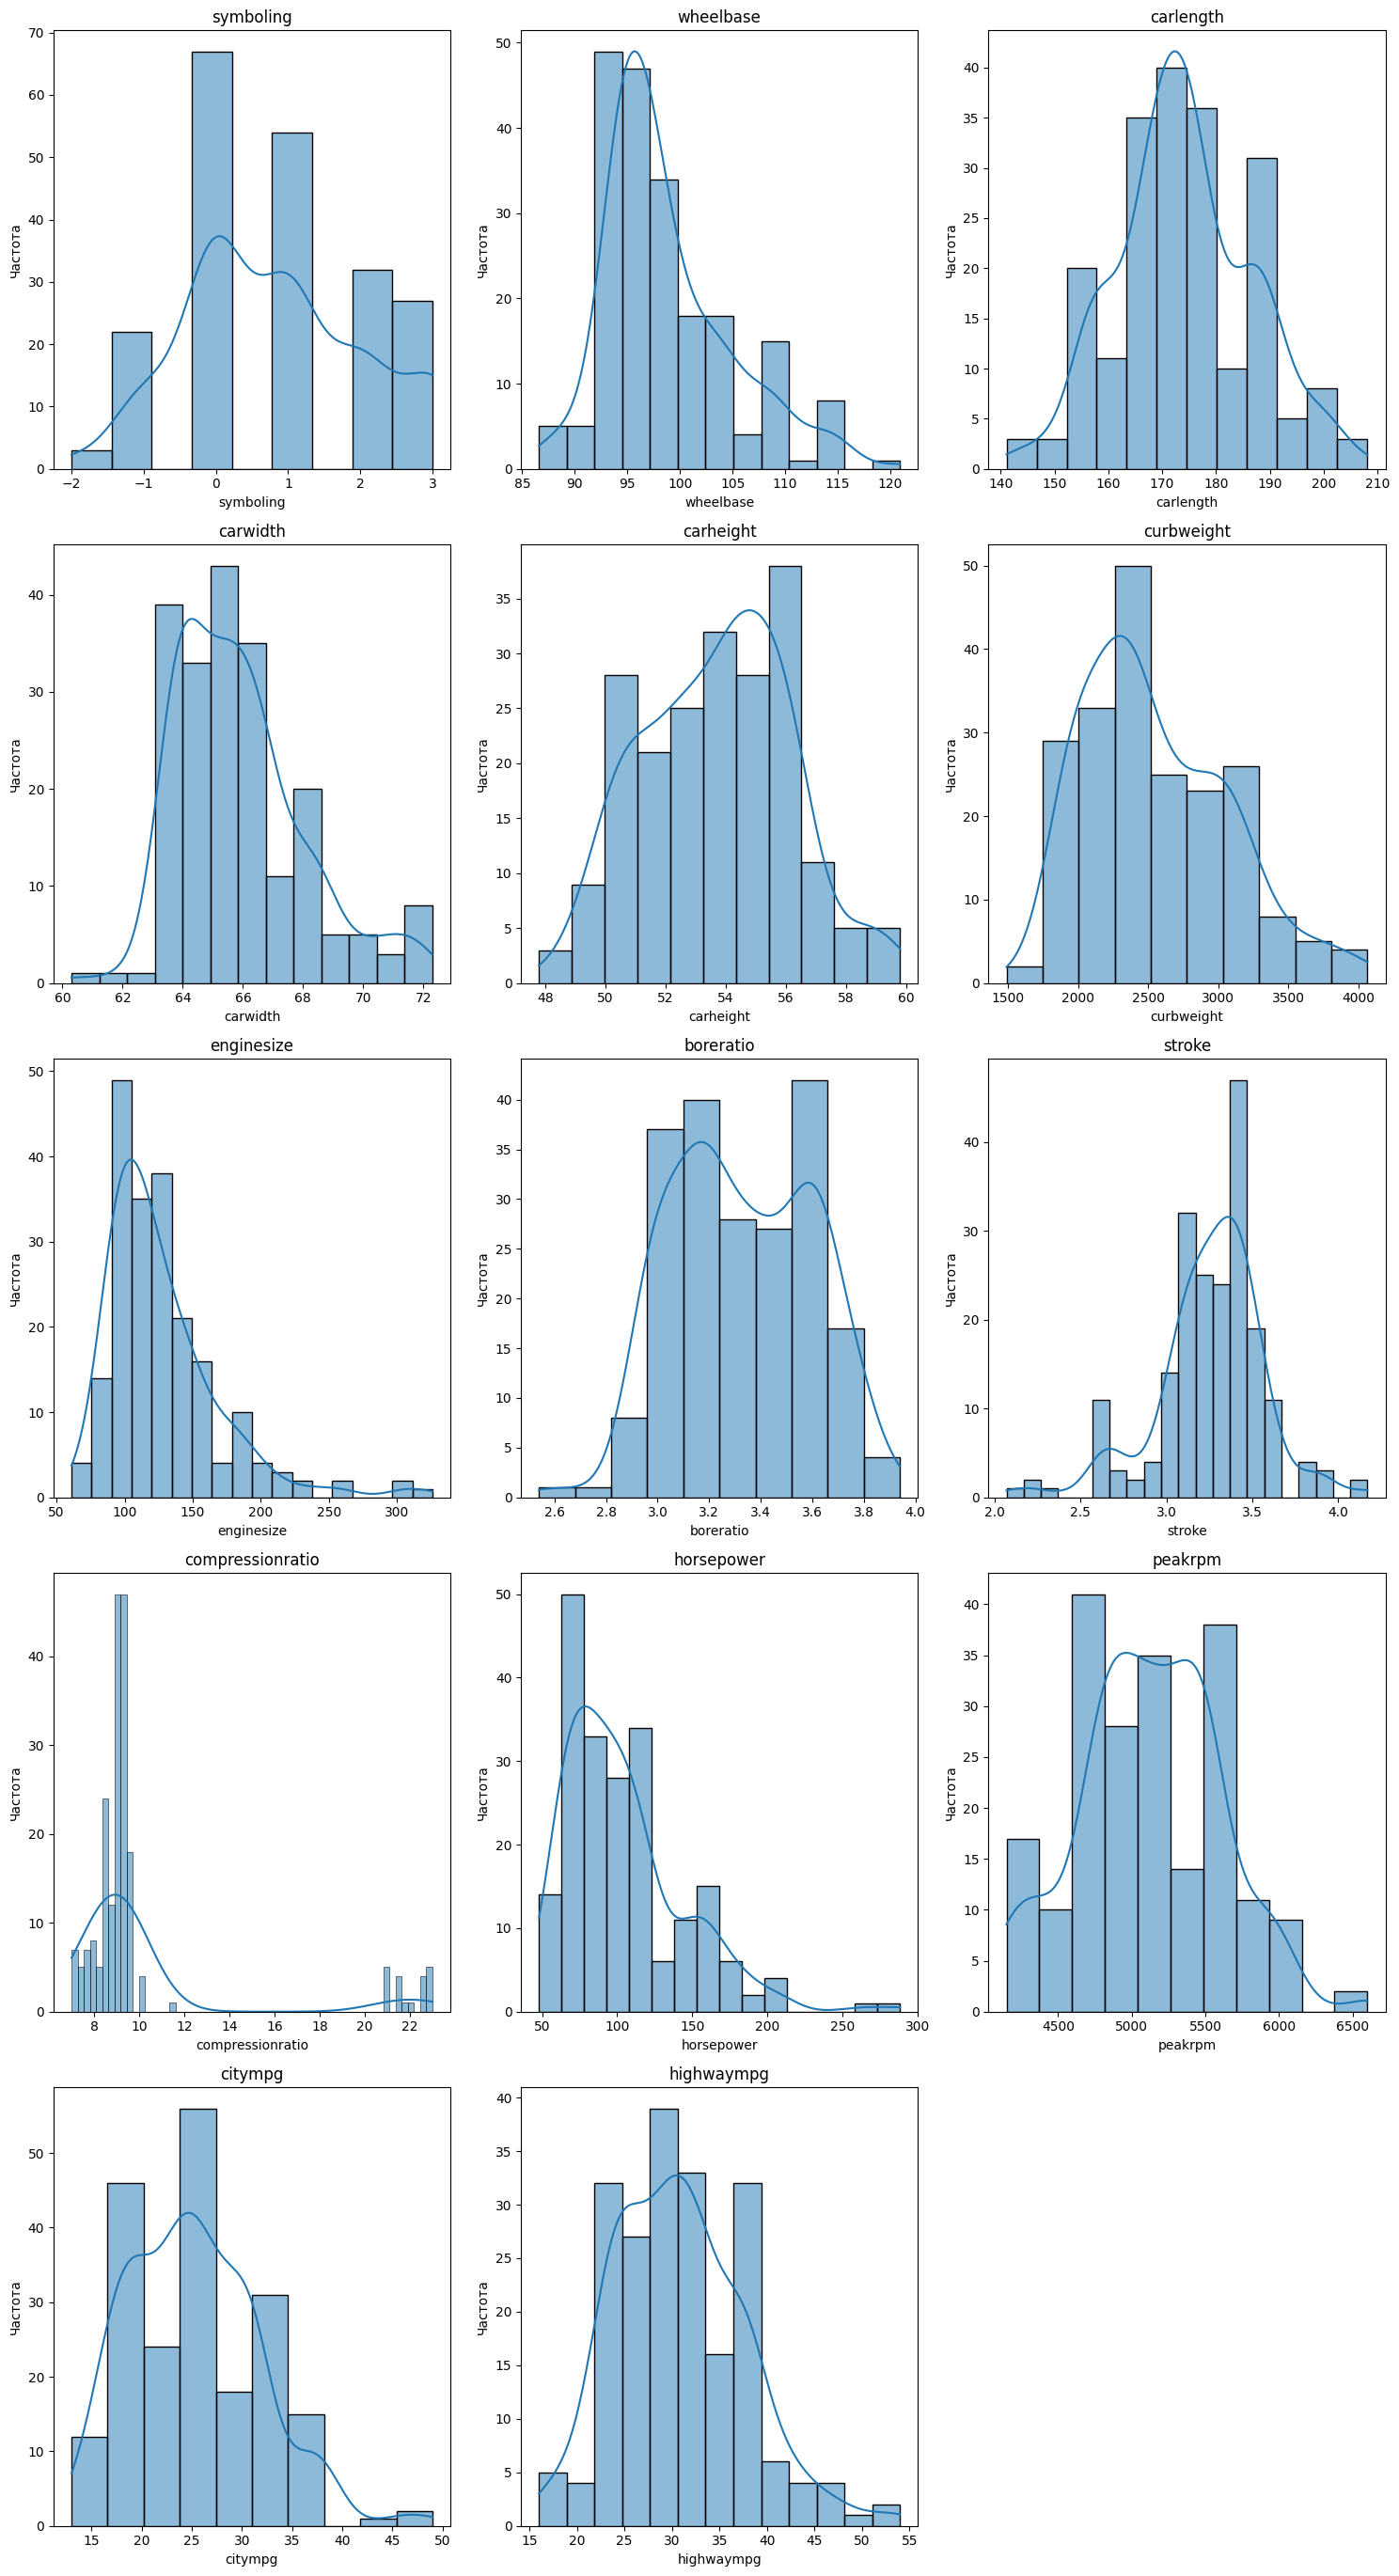

In [26]:
n_cols = 3
n_rows = int(np.ceil(len(numeric_initial) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5.5 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, numeric_initial):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Частота")

for ax in axes[len(numeric_initial):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [27]:
X = df_model.drop(columns="price")
y = df_model["price"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)
id_train = ids.loc[X_train.index]
id_test = ids.loc[X_test.index]

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (164, 23) Test: (41, 23)


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [29]:
continuous_cols = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c != "symboling"
]

q1 = X_train[continuous_cols].quantile(0.25)
q3 = X_train[continuous_cols].quantile(0.75)

iqr = q3 - q1

lower_bounds = q1 - 1.5 * iqr
upper_bounds = q3 + 1.5 * iqr

outlier_counts = (
    (X_train[continuous_cols] < lower_bounds)
    | (X_train[continuous_cols] > upper_bounds)
).sum().sort_values(ascending=False)

display(outlier_counts.to_frame("potential_outliers_train"))

X_train = X_train.copy()
X_test = X_test.copy()

X_train[continuous_cols] = X_train[continuous_cols].clip(
    lower=lower_bounds,
    upper=upper_bounds,
    axis=1
)

,potential_outliers_train
compressionratio,20
stroke,16
carwidth,10
horsepower,7
enginesize,7
wheelbase,6
peakrpm,2
highwaympg,1
boreratio,1
curbweight,0


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


In [ ]:
numeric_train_cols = X_train.select_dtypes(include=np.number).columns

corr = X_train[numeric_train_cols].corr().abs()

plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    cmap="crest"
    annot=True,
    fmt=".2f",
    mask=np.triu(np.ones_like(corr, dtype=bool)),
    square=True,
    cbar=False,
)

plt.title("Матриця")

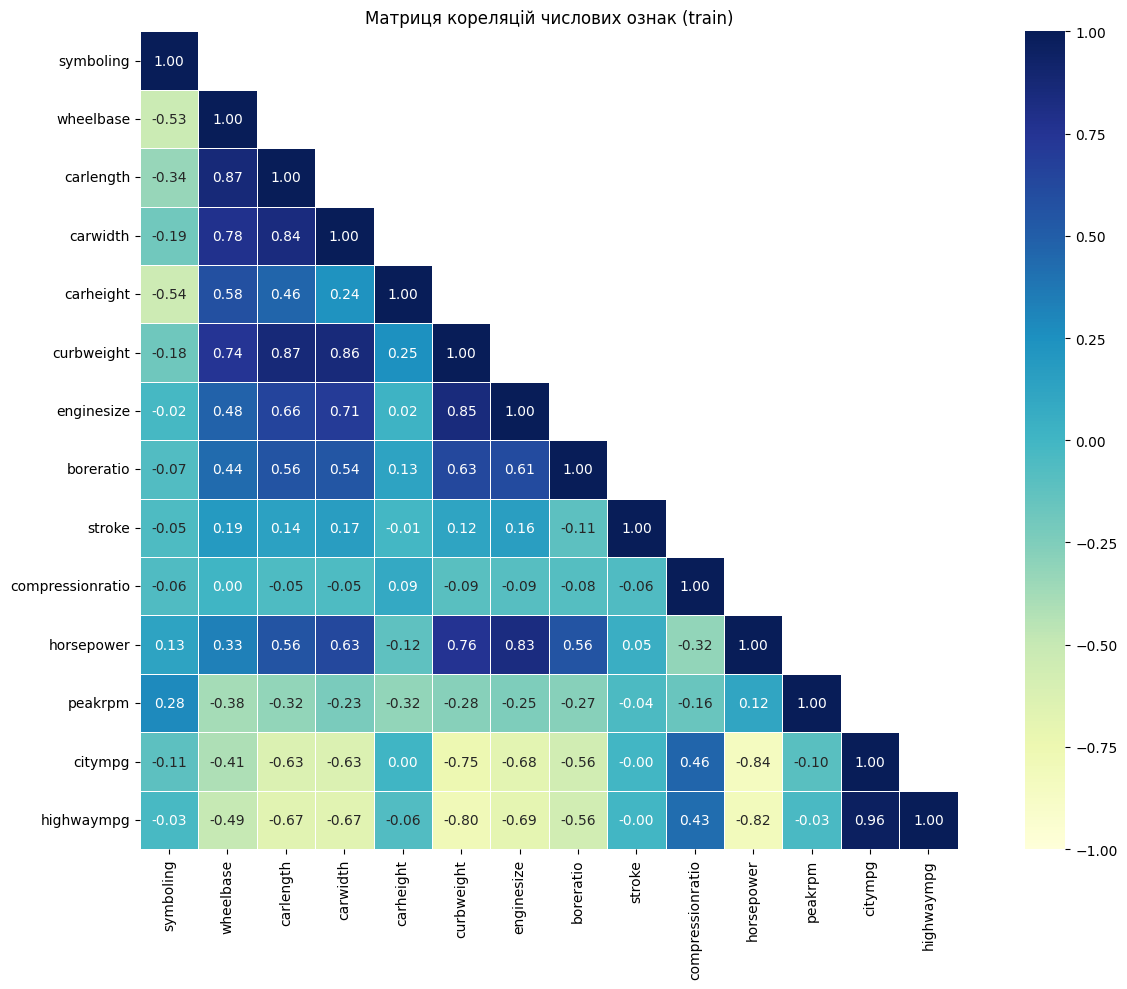

Сильно корельовані пари (|r| > 0.85):
wheelbase — carlength: 0.867; зв'язок із price: 0.504 та 0.652
carlength — curbweight: 0.866; зв'язок із price: 0.652 та 0.824
carwidth — curbweight: 0.858; зв'язок із price: 0.732 та 0.824
citympg — highwaympg: 0.964; зв'язок із price: 0.711 та 0.716

Ознаки, які видаляються:
['carlength', 'carwidth', 'citympg', 'wheelbase']

Розмір train після відбору: (164, 19)
Розмір test після відбору: (41, 19)

Ознаки, що залишилися:
['symboling', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']


In [30]:
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()

corr_matrix = X_train[numeric_cols].corr()

price_corr = X_train[numeric_cols].corrwith(y_train).abs()

# Теплова карта кореляцій
plt.figure(figsize=(14, 10))

mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Матриця кореляцій числових ознак (train)")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Знаходимо пари ознак із сильною кореляцією |r| > 0.85
strong_pairs = []

for i in range(len(numeric_cols)):
    for j in range(i + 1, len(numeric_cols)):
        col1 = numeric_cols[i]
        col2 = numeric_cols[j]
        corr_value = corr_matrix.loc[col1, col2]

        if abs(corr_value) > 0.85:
            strong_pairs.append(
                (col1, col2, corr_value)
            )

print("Сильно корельовані пари (|r| > 0.85):")

if strong_pairs:
    for col1, col2, corr_value in strong_pairs:
        print(
            f"{col1} — {col2}: {corr_value:.3f}; "
            f"зв'язок із price: "
            f"{price_corr[col1]:.3f} та "
            f"{price_corr[col2]:.3f}"
        )
else:
    print("Пар із |r| > 0.85 не знайдено.")

features_to_drop = set()

for col1, col2, corr_value in strong_pairs:
    if col1 in features_to_drop or col2 in features_to_drop:
        continue

    if price_corr[col1] < price_corr[col2]:
        features_to_drop.add(col1)
    else:
        features_to_drop.add(col2)

print("\nОзнаки, які видаляються:")
print(sorted(features_to_drop))

# Видаляємо однакові ознаки з train і test
X_train = X_train.drop(
    columns=list(features_to_drop),
    errors="ignore"
)

X_test = X_test.drop(
    columns=list(features_to_drop),
    errors="ignore"
)

print("\nРозмір train після відбору:", X_train.shape)
print("Розмір test після відбору:", X_test.shape)
print("\nОзнаки, що залишилися:")
print(X_train.columns.tolist())

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [31]:
# Дискретна числова ознака
discrete_cols = ["symboling"] if "symboling" in X_train.columns else []

# Категоріальні ознаки
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Неперервні числові ознаки
continuous_cols = [
    col for col in X_train.select_dtypes(include=np.number).columns
    if col not in discrete_cols
]

print("Неперервні числові ознаки:")
print(continuous_cols)

print("\nДискретні числові ознаки:")
print(discrete_cols)

print("\nКатегоріальні ознаки:")
print(categorical_cols)


# Створюємо конвеєри передобробки
continuous_pipeline = Pipeline([
    ("yeo_johnson", PowerTransformer(method="yeo-johnson")),
    ("scaler", StandardScaler())
])

discrete_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


# Об'єднуємо всі перетворення
preprocessor = ColumnTransformer(
    transformers=[
        ("continuous", continuous_pipeline, continuous_cols),
        ("discrete", discrete_pipeline, discrete_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ],
    remainder="drop"
)


# Навчаємо механізм тільки на train
X_train_processed = preprocessor.fit_transform(X_train)

# Для test застосовуємо вже навчені перетворення
X_test_processed = preprocessor.transform(X_test)


# Перевіряємо результати
print("\nРозмір X_train до перетворення:", X_train.shape)
print("Розмір X_test до перетворення:", X_test.shape)

print("\nРозмір X_train після перетворення:",
      X_train_processed.shape)
print("Розмір X_test після перетворення:",
      X_test_processed.shape)

print("\nЧи є пропущені значення в обробленому train:",
      np.isnan(X_train_processed).any())

print("Чи є пропущені значення в обробленому test:",
      np.isnan(X_test_processed).any())

Неперервні числові ознаки:
['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']

Дискретні числові ознаки:
['symboling']

Категоріальні ознаки:
['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']

Розмір X_train до перетворення: (164, 19)
Розмір X_test до перетворення: (41, 19)

Розмір X_train після перетворення: (164, 47)
Розмір X_test після перетворення: (41, 47)

Чи є пропущені значення в обробленому train: False
Чи є пропущені значення в обробленому test: False


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [37]:
# Початкові неперервні числові ознаки
numeric_initial = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in ["car_ID", "price", "symboling"]
]

# Використовуємо навчальні рядки, що потрапили до train
X_continuous_initial = df.loc[X_train.index, numeric_initial].copy()

# Межі викидів з початкового етапу, якщо вони збережені,
# можна застосувати тут для узгодження з попереднім аналізом.

# Перетворення Yeo-Johnson
yeo_johnson = PowerTransformer(method="yeo-johnson")
X_yj = yeo_johnson.fit_transform(X_continuous_initial)

df_yj = pd.DataFrame(
    X_yj,
    columns=numeric_initial,
    index=X_train.index
)

# Таблиця асиметрії після перетворення
skewness_after = (
    df_yj.skew()
    .to_frame(name="skewness_after")
    .sort_values("skewness_after", key=abs)
)

display(skewness_after)

,skewness_after
carwidth,0.000000
peakrpm,-0.001853
carlength,0.002608
carheight,-0.005170
boreratio,-0.006837
compressionratio,0.006866
citympg,-0.008044
highwaympg,-0.008701
wheelbase,0.015858
enginesize,0.033719


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [41]:
estimators = {
    "Linear Regression": LinearRegression(),

    "Ridge": Ridge(
        alpha=1.0
    ),

    "Lasso": Lasso(
        alpha=1.0,
        max_iter=20000
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "SVR": SVR()
}

# 2. Створюємо Pipeline для кожної моделі
models = {
    name: Pipeline(steps=[
        ("preprocess", clone(preprocessor)),
        ("model", clone(estimator))
    ])
    for name, estimator in estimators.items()
}

# 3. Навчаємо кожну модель
for name, model in models.items():
    model.fit(X_train, y_train)

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [42]:
results = []

for name, model in models.items():
    # Прогноз на тестовій вибірці
    y_pred = model.predict(X_test)

    # Обчислення метрик
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    results.append({
        "Model": name,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "MAPE (%)": mape
    })

# Створюємо таблицю та сортуємо за R2
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

# Виводимо результати
display(
    results_df.style.format({
        "R2": "{:.4f}",
        "MAE": "{:.2f}",
        "MSE": "{:.2f}",
        "MAPE (%)": "{:.2f}%"
    })
)

,Model,R2,MAE,MSE,MAPE (%)
0,Random Forest,0.9531,1419.23,3700864.75,10.58%
1,Gradient Boosting,0.9303,1720.21,5503233.87,12.17%
2,Lasso,0.8365,2578.15,12904122.58,20.42%
3,Linear Regression,0.8190,2761.56,14285052.89,23.39%
4,Ridge,0.8131,2653.92,14753469.42,23.15%
5,SVR,-0.1000,5697.51,86835223.96,36.03%


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


**Пояснення вибору типу моделі**

Прогнозування ціни автомобіля належить до задач регресії, оскільки цільова змінна price є неперервною числовою величиною. Регресійні моделі дають змогу передбачати конкретне числове значення вартості автомобіля на основі його характеристик.

Класифікаційна модель Logistic Regression не підходить для безпосереднього прогнозування неперервної ціни, оскільки вона призначена для визначення ймовірностей належності об'єкта до певного класу. Для використання класифікації ціну довелося б попередньо розділити на категорії, що призвело б до втрати точності числового прогнозу.

У роботі використано Linear Regression, Ridge Regression, Lasso Regression, Random Forest Regressor, Gradient Boosting Regressor та Support Vector Regressor. Ці алгоритми призначені для регресійних задач, але відрізняються принципами побудови залежності між характеристиками автомобіля та його ціною. Це дає змогу порівняти лінійні й нелінійні підходи та визначити найефективнішу модель для досліджуваного набору даних.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


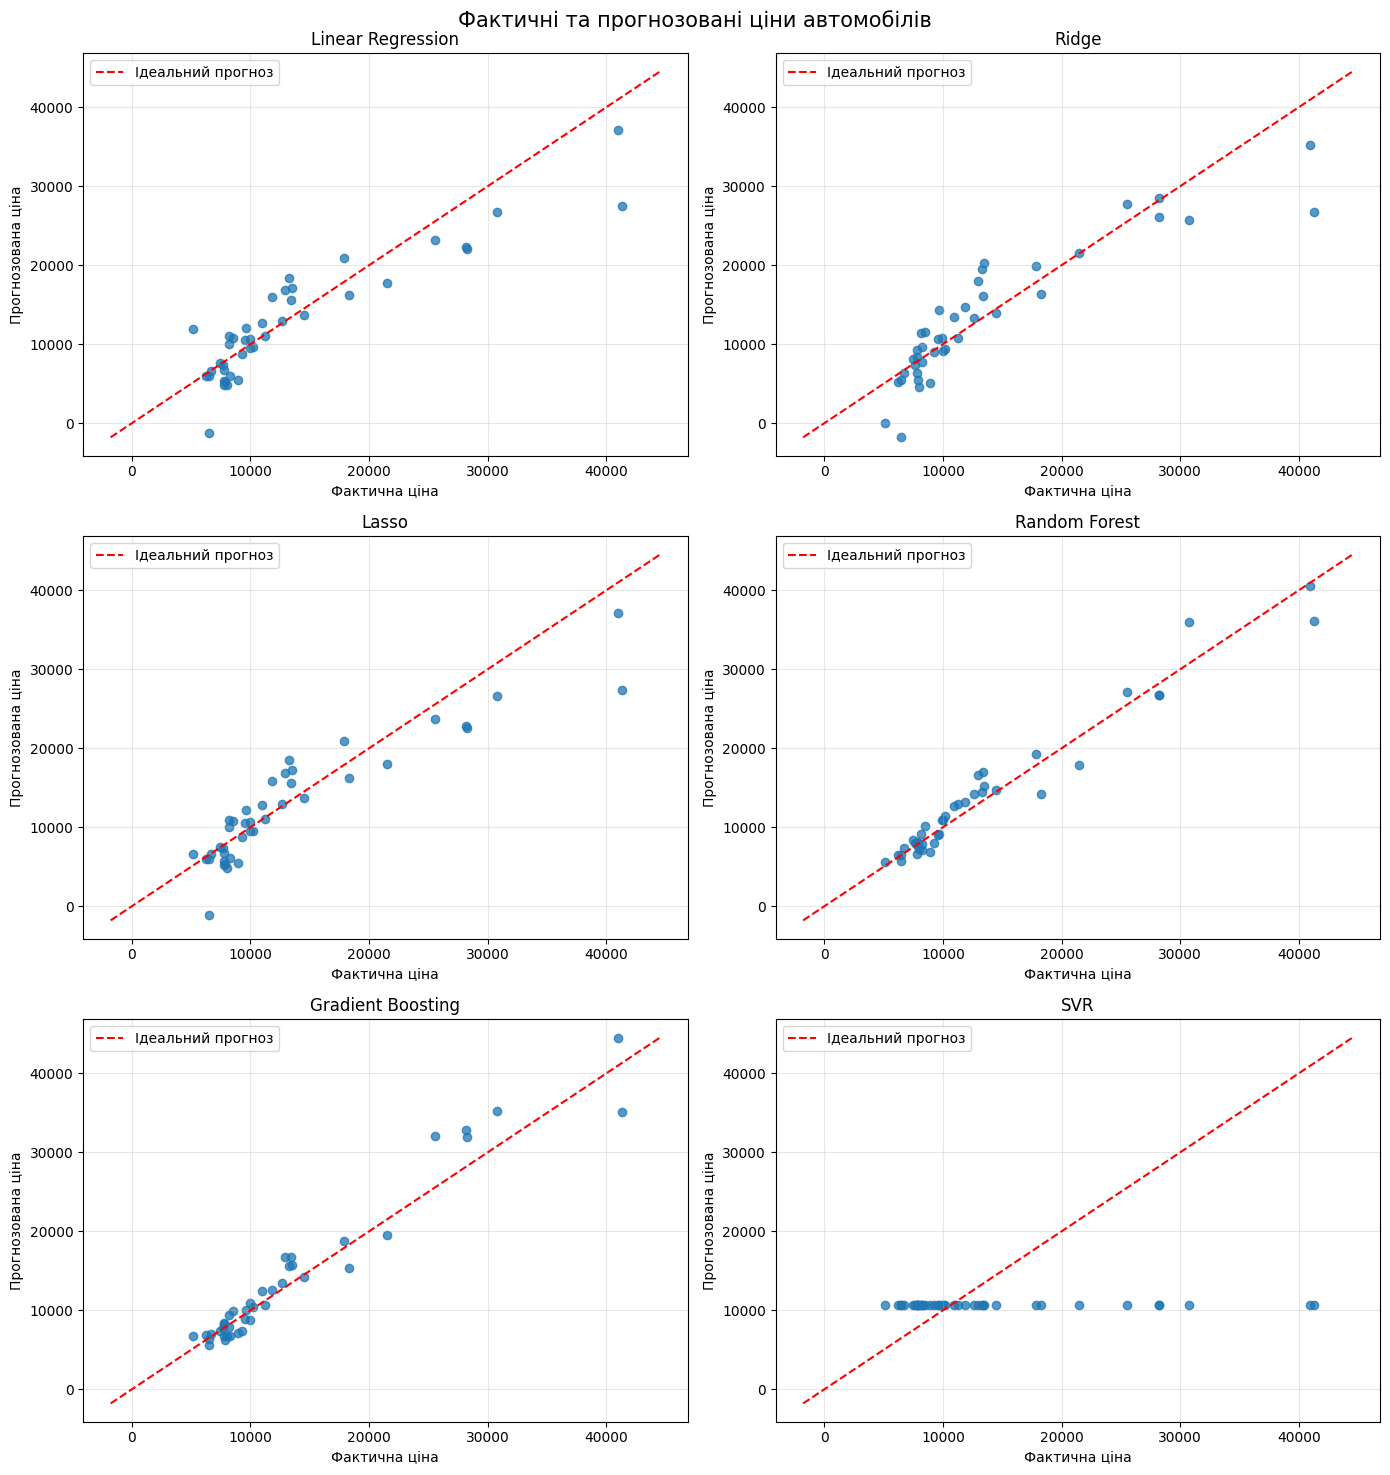

In [43]:
n_models = len(models)
n_cols = 2
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(14, 5 * n_rows)
)

axes = np.array(axes).reshape(-1)

y_true = np.asarray(y_test)

# Спільні межі для всіх графіків
all_predictions = [
    model.predict(X_test) for model in models.values()
]

min_value = min(
    y_true.min(),
    min(pred.min() for pred in all_predictions)
)
max_value = max(
    y_true.max(),
    max(pred.max() for pred in all_predictions)
)

for ax, (name, model), y_pred in zip(
    axes, models.items(), all_predictions
):
    ax.scatter(
        y_true,
        y_pred,
        alpha=0.75
    )

    # Лінія ідеального прогнозу
    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        "r--",
        label="Ідеальний прогноз"
    )

    ax.set_title(name)
    ax.set_xlabel("Фактична ціна")
    ax.set_ylabel("Прогнозована ціна")
    ax.legend()
    ax.grid(True, alpha=0.3)

# Приховуємо зайві осі, якщо вони є
for ax in axes[n_models:]:
    ax.axis("off")

plt.suptitle(
    "Фактичні та прогнозовані ціни автомобілів",
    fontsize=15
)
plt.tight_layout()
plt.show()


## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [44]:
sample_ids = X_test.sample(
    n=min(10, len(X_test)),
    random_state=42
).index

X_sample = X_test.loc[sample_ids]

# Фактичні ціни
y_actual = y_test.loc[sample_ids]

# Прогнози Random Forest
rf_model = models["Random Forest"]
y_predicted = rf_model.predict(X_sample)

# Формуємо порівняльну таблицю
predictions_df = pd.DataFrame({
    "car_ID": id_test.loc[sample_ids].values,
    "Actual Price": y_actual.values,
    "Predicted Price": y_predicted,
    "Absolute Error": np.abs(
        y_actual.values - y_predicted
    ),
    "Absolute Percentage Error (%)": (
        np.abs(y_actual.values - y_predicted)
        / np.abs(y_actual.values).clip(min=1e-10)
    ) * 100
})

display(
    predictions_df.style.format({
        "Actual Price": "{:.2f}",
        "Predicted Price": "{:.2f}",
        "Absolute Error": "{:.2f}",
        "Absolute Percentage Error (%)": "{:.2f}%"
    })
)


,car_ID,Actual Price,Predicted Price,Absolute Error,Absolute Percentage Error (%)
0,26,6692.00,7348.39,656.39,9.81%
1,176,9988.00,10899.76,911.76,9.13%
2,148,10198.00,11369.76,1171.76,11.49%
3,17,41315.00,36096.49,5218.51,12.63%
4,69,28248.00,26690.66,1557.34,5.51%
5,147,7463.00,8416.78,953.78,12.78%
6,144,9960.00,10932.52,972.52,9.76%
7,85,14489.00,14670.42,181.42,1.25%
8,195,12940.00,16599.96,3659.96,28.28%
9,160,7788.00,7773.52,14.48,0.19%


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


**Висновки:** У лабораторній роботі було виконано підготовку датасету Car Price Prediction та побудовано шість регресійних моделей для прогнозування ціни автомобілів. Під час підготовки даних було перевірено якість даних, проаналізовано викиди та кореляції між ознаками, виконано перетворення Yeo–Johnson, стандартизацію числових ознак і кодування категоріальних змінних методом One-Hot Encoding.

Якість моделей оцінювалася за метриками R², MAE, MSE та MAPE. Найкращі результати на тестовій вибірці показав Random Forest Regressor: R² = 0,9531, MAE = 1419,23, MSE = 3700864,75 та MAPE = 10,58%. Це свідчить про високу точність прогнозування ціни автомобілів цією моделлю на досліджуваній тестовій вибірці. Друге місце посів Gradient Boosting Regressor із R² = 0,9303 та MAPE = 12,17%.

Моделі Lasso, Linear Regression і Ridge показали помірні результати, тоді як SVR продемонструвала найгіршу якість: R² = −0,1000 та MAPE = 36,03%. Від'ємне значення R² означає, що прогнози SVR на тестовій вибірці виявилися гіршими за простий прогноз середнім значенням цільової змінної.

Візуальне порівняння фактичних і прогнозованих цін та аналіз прогнозів десяти автомобілів дають змогу додатково оцінити точність моделей і виявити випадки значних відхилень. Можливе перенавчання перевіряється шляхом порівняння результатів на навчальній і тестовій вибірках. Використання єдиного механізму передобробки забезпечило однакові правила підготовки даних для всіх моделей і допомогло уникнути витоку інформації з тестової вибірки.

Отже, для цього набору даних Random Forest Regressor виявився найефективнішою з перевірених моделей за всіма чотирма метриками. Отримані результати демонструють важливість попередньої обробки даних, правильного вибору алгоритму та комплексного оцінювання якості регресійних моделей.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
